# Transferencia de conocimiento

In [1]:
import os

import torch
import torch.nn as nn
from torchvision import models
from sklearn.metrics import classification_report

from utilidades import (crear_dataloaders, entrenar, evaluar, guardar_resultado, guardar_acc_test, dibujar_curvas,
                        dibujar_matriz_confusion, device, MEDIA_IMAGENET, DESVIACION_IMAGENET)

torch.manual_seed(42)
os.makedirs('modelos', exist_ok=True)
print(f'Usando dispositivo: {device}')

Usando dispositivo: cuda


## Carga de datos con la normalización de ImageNet

In [2]:
tam_imagen = 224
tam_lote = 32
epocas_max = 20
paciencia = 5

dataloader_entrenamiento, dataloader_validacion, dataloader_test, clases = crear_dataloaders(
    'datos', tam_imagen, tam_lote, media=MEDIA_IMAGENET, desviacion=DESVIACION_IMAGENET)

print(f'Nombre de las etiquetas: {clases}')

Nombre de las etiquetas: ['cushion', 'emerald', 'heart', 'oval', 'pear', 'princess', 'round']


## ResNet18 como extractor de características

In [3]:
resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

for parametro in resnet.parameters():
    parametro.requires_grad = False

resnet.fc = nn.Linear(resnet.fc.in_features, len(clases))
resnet = resnet.to(device)

parametros_entrenables = sum(p.numel() for p in resnet.parameters() if p.requires_grad)
parametros_totales = sum(p.numel() for p in resnet.parameters())
print(f'Parámetros entrenables: {parametros_entrenables} de {parametros_totales}')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\danie/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


0.3%

0.6%

0.8%

1.1%

...

99.4%

99.6%

99.9%

100.0%

Parámetros entrenables: 3591 de 11180103


Época [ 1/20] | Train Loss: 0.1827 | Train Acc: 0.9644 | Val Loss: 0.0354 | Val Acc: 0.9944 *


Época [ 2/20] | Train Loss: 0.0450 | Train Acc: 0.9919 | Val Loss: 0.0251 | Val Acc: 0.9955 *


Época [ 3/20] | Train Loss: 0.0348 | Train Acc: 0.9938 | Val Loss: 0.0178 | Val Acc: 0.9966 *


Época [ 4/20] | Train Loss: 0.0281 | Train Acc: 0.9939 | Val Loss: 0.0168 | Val Acc: 0.9978 *


Época [ 5/20] | Train Loss: 0.0234 | Train Acc: 0.9958 | Val Loss: 0.0148 | Val Acc: 0.9978 *


...

Época [16/20] | Train Loss: 0.0105 | Train Acc: 0.9979 | Val Loss: 0.0121 | Val Acc: 0.9978 


Época [17/20] | Train Loss: 0.0189 | Train Acc: 0.9969 | Val Loss: 0.0118 | Val Acc: 0.9978 


Época [18/20] | Train Loss: 0.0160 | Train Acc: 0.9963 | Val Loss: 0.0120 | Val Acc: 0.9980 


Época [19/20] | Train Loss: 0.0103 | Train Acc: 0.9974 | Val Loss: 0.0131 | Val Acc: 0.9975 


Época [20/20] | Train Loss: 0.0076 | Train Acc: 0.9984 | Val Loss: 0.0137 | Val Acc: 0.9969 
Parada anticipada: 5 épocas sin mejorar la pérdida de validación
Mejor época: 15 | Tiempo total: 787.8 segundos


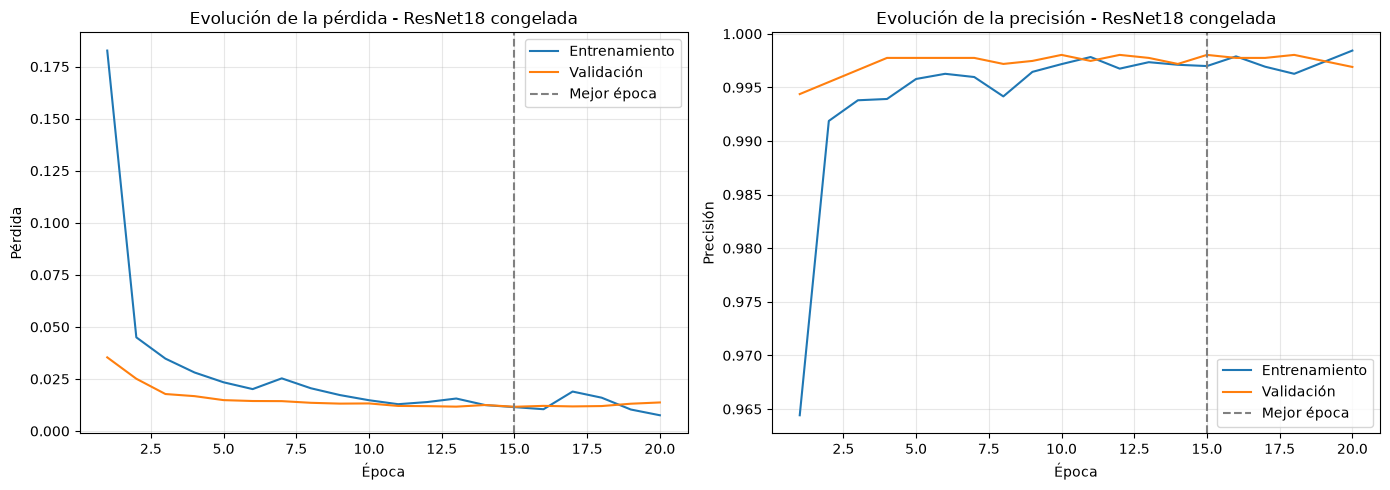

In [4]:
historial_congelada = entrenar(resnet, dataloader_entrenamiento, dataloader_validacion, lr=0.001,
                               epocas_max=epocas_max, paciencia=paciencia,
                               ruta_modelo='modelos/TL-ResNet18-congelada.pth')

guardar_resultado('TL-ResNet18-congelada', {'tam_imagen': tam_imagen, 'tam_lote': tam_lote, 'lr': 0.001,
                                             'capas_entrenadas': 'fc'}, historial_congelada)
dibujar_curvas(historial_congelada, 'ResNet18 congelada', 'graficas/curvas_TL-ResNet18-congelada.png')

## ResNet18 con ajuste fino de todas las capas

Época [ 1/20] | Train Loss: 0.0333 | Train Acc: 0.9948 | Val Loss: 0.0102 | Val Acc: 0.9983 *


Época [ 2/20] | Train Loss: 0.0071 | Train Acc: 0.9981 | Val Loss: 0.0083 | Val Acc: 0.9989 *


Época [ 3/20] | Train Loss: 0.0019 | Train Acc: 0.9996 | Val Loss: 0.0120 | Val Acc: 0.9989 


Época [ 4/20] | Train Loss: 0.0064 | Train Acc: 0.9987 | Val Loss: 0.0269 | Val Acc: 0.9952 


Época [ 5/20] | Train Loss: 0.0160 | Train Acc: 0.9971 | Val Loss: 0.0080 | Val Acc: 0.9989 *


...

Época [ 7/20] | Train Loss: 0.0038 | Train Acc: 0.9989 | Val Loss: 0.0064 | Val Acc: 0.9986 


Época [ 8/20] | Train Loss: 0.0044 | Train Acc: 0.9998 | Val Loss: 0.0076 | Val Acc: 0.9992 


Época [ 9/20] | Train Loss: 0.0064 | Train Acc: 0.9983 | Val Loss: 0.0084 | Val Acc: 0.9989 


Época [10/20] | Train Loss: 0.0037 | Train Acc: 0.9992 | Val Loss: 0.0100 | Val Acc: 0.9980 


Época [11/20] | Train Loss: 0.0083 | Train Acc: 0.9982 | Val Loss: 0.0071 | Val Acc: 0.9986 
Parada anticipada: 5 épocas sin mejorar la pérdida de validación
Mejor época: 6 | Tiempo total: 640.7 segundos


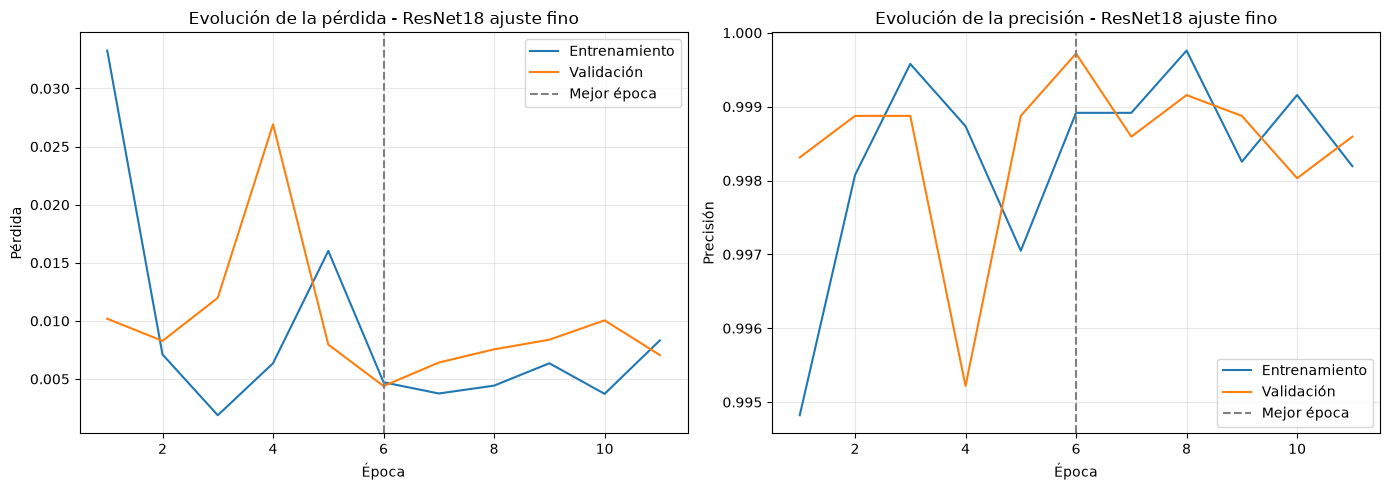

In [5]:
for parametro in resnet.parameters():
    parametro.requires_grad = True

historial_ajuste_fino = entrenar(resnet, dataloader_entrenamiento, dataloader_validacion, lr=0.0001,
                                 epocas_max=epocas_max, paciencia=paciencia,
                                 ruta_modelo='modelos/TL-ResNet18-ajuste-fino.pth')

guardar_resultado('TL-ResNet18-ajuste-fino', {'tam_imagen': tam_imagen, 'tam_lote': tam_lote, 'lr': 0.0001,
                                               'capas_entrenadas': 'todas'}, historial_ajuste_fino)
dibujar_curvas(historial_ajuste_fino, 'ResNet18 ajuste fino', 'graficas/curvas_TL-ResNet18-ajuste-fino.png')

## MobileNetV2 con ajuste fino de todas las capas

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to C:\Users\danie/.cache\torch\hub\checkpoints\mobilenet_v2-7ebf99e0.pth


0.9%

1.8%

2.8%

3.7%

...

Época [ 4/20] | Train Loss: 0.0029 | Train Acc: 0.9993 | Val Loss: 0.0065 | Val Acc: 0.9992 


Época [ 5/20] | Train Loss: 0.0019 | Train Acc: 0.9994 | Val Loss: 0.0065 | Val Acc: 0.9992 


Época [ 6/20] | Train Loss: 0.0042 | Train Acc: 0.9992 | Val Loss: 0.0107 | Val Acc: 0.9980 


Época [ 7/20] | Train Loss: 0.0050 | Train Acc: 0.9986 | Val Loss: 0.0063 | Val Acc: 0.9992 


Época [ 8/20] | Train Loss: 0.0013 | Train Acc: 0.9997 | Val Loss: 0.0081 | Val Acc: 0.9992 
Parada anticipada: 5 épocas sin mejorar la pérdida de validación
Mejor época: 3 | Tiempo total: 551.3 segundos


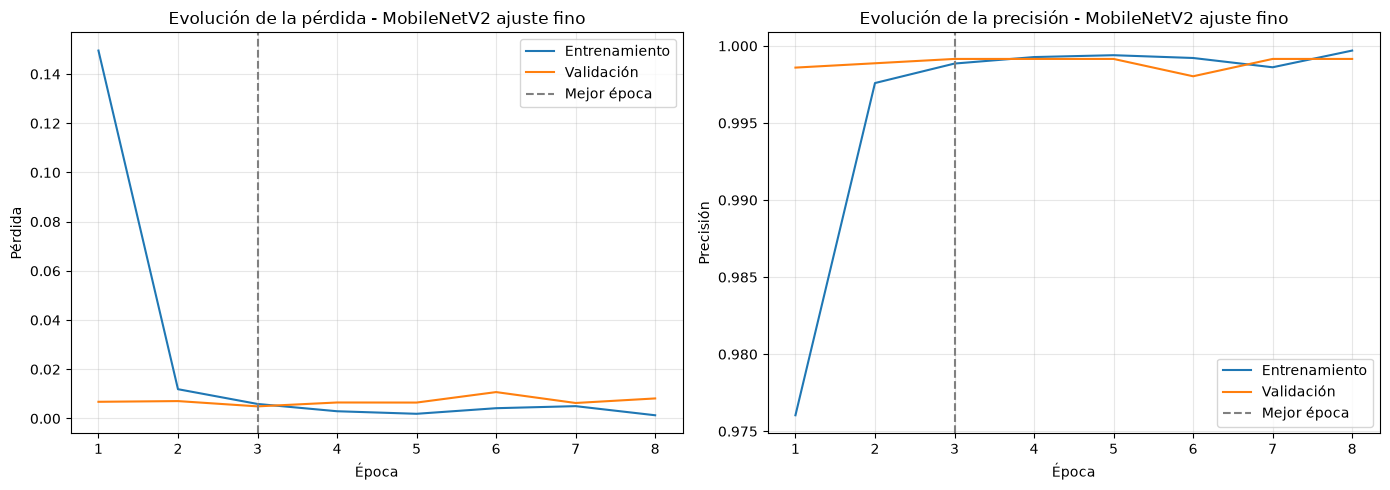

In [6]:
torch.manual_seed(42)
mobilenet = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
mobilenet.classifier[1] = nn.Linear(mobilenet.classifier[1].in_features, len(clases))
mobilenet = mobilenet.to(device)

historial_mobilenet = entrenar(mobilenet, dataloader_entrenamiento, dataloader_validacion, lr=0.0001,
                               epocas_max=epocas_max, paciencia=paciencia,
                               ruta_modelo='modelos/TL-MobileNetV2-ajuste-fino.pth')

guardar_resultado('TL-MobileNetV2-ajuste-fino', {'tam_imagen': tam_imagen, 'tam_lote': tam_lote, 'lr': 0.0001,
                                                  'capas_entrenadas': 'todas'}, historial_mobilenet)
dibujar_curvas(historial_mobilenet, 'MobileNetV2 ajuste fino', 'graficas/curvas_TL-MobileNetV2-ajuste-fino.png')

## Comparación en validación

In [7]:
modelos_tl = {
    'ResNet18 congelada': (None, historial_congelada),
    'ResNet18 ajuste fino': (resnet, historial_ajuste_fino),
    'MobileNetV2 ajuste fino': (mobilenet, historial_mobilenet),
}

for nombre, (_, historial) in modelos_tl.items():
    mejor = historial['mejor_epoca'] - 1
    print(f'{nombre:24s} | mejor época: {historial["mejor_epoca"]:2d} | '
          f'loss val: {historial["perdida_val"][mejor]:.4f} | acc val: {historial["acc_val"][mejor]:.4f} | '
          f'tiempo: {historial["tiempo"]:.0f} s')

ResNet18 congelada       | mejor época: 15 | loss val: 0.0116 | acc val: 0.9980 | tiempo: 788 s
ResNet18 ajuste fino     | mejor época:  6 | loss val: 0.0044 | acc val: 0.9997 | tiempo: 641 s
MobileNetV2 ajuste fino  | mejor época:  3 | loss val: 0.0049 | acc val: 0.9992 | tiempo: 551 s


## Evaluación en test del mejor modelo de transferencia

In [8]:
nombre_mejor = min(['ResNet18 ajuste fino', 'MobileNetV2 ajuste fino'],
                   key=lambda nombre: min(modelos_tl[nombre][1]['perdida_val']))
modelo_mejor = modelos_tl[nombre_mejor][0]

y_real, y_pred, perdida_test, acc_test = evaluar(modelo_mejor, dataloader_test)
guardar_acc_test(f"TL-{nombre_mejor.replace(' ', '-')}", acc_test)

print(f'Mejor modelo: {nombre_mejor}')
print(f'Test Loss: {perdida_test:.4f} | Test Acc: {acc_test:.4f}')
print(classification_report(y_real, y_pred, target_names=clases, digits=4))

Mejor modelo: ResNet18 ajuste fino
Test Loss: 0.0100 | Test Acc: 0.9994
              precision    recall  f1-score   support

     cushion     1.0000    1.0000    1.0000       510
     emerald     0.9980    1.0000    0.9990       510
       heart     1.0000    0.9980    0.9990       510
        oval     1.0000    1.0000    1.0000       510
        pear     1.0000    0.9980    0.9990       510
    princess     1.0000    1.0000    1.0000       510
       round     0.9980    1.0000    0.9990       510

    accuracy                         0.9994      3570
   macro avg     0.9994    0.9994    0.9994      3570
weighted avg     0.9994    0.9994    0.9994      3570



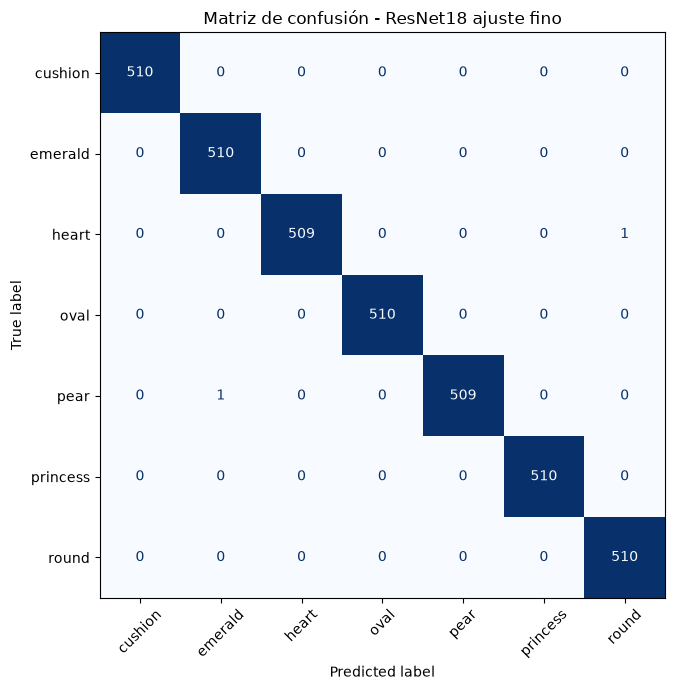

In [9]:
dibujar_matriz_confusion(y_real, y_pred, clases, nombre_mejor, 'graficas/matriz_TL-mejor.png')